# GH-I model

After trying `test-0-x`, now, we proceed to propose canonical toy models for the paper and test basic properties, preparing for scanning.

`test-1-x` are for the main text gate-head (GH) model, which is more like `MoE`. We need to balance the simplicty of the model and the generalizability (can connect to different architectures).

In this model, the input $x\in \mathbb{R}^m$ is like query. We have a key matrix $K \in \mathbb{R}^{d\times m}$, and a value tensor $V \in \mathbb{R}^{d\times m \times m}$. The output of the gate is computed as:
$$
h =  (Vx)^T \mathrm{Softmax}(Kx) \in \mathbb{R}^m.
$$
We call this part G-I, gate model type I.
After the gate, we project the hidden state out with a head $W \in \mathbb{R}^{n\times m}$, and the final logits is:
$$
y = Wh \in \mathbb{R}^n.
$$

Visually, one can see
<img src="GHmodels.jpeg" alt="GHmodels" width="600">

We want the toy model to have the following properties:
- 1/3 scaling for gate part
- 3/4 situations of GH can show the 1/3 scaling, 1/4 situation means both high temperature.
- Maybe increasing Hessian, not necessary.

## G-I model

`test-1` is for testing G-I.

`test-1-1` is to test the hypothesis in `test-1` about qk Hessian increase.

In [14]:
import torch
import torch.nn.functional as F
import torch.nn as nn
from dataclasses import dataclass
import matplotlib.pyplot as plt

In [15]:
from scipy.sparse.linalg import LinearOperator, eigsh
import numpy as np

def prepare_hvp(loss, params):
    grads = torch.autograd.grad(loss, params, create_graph=True)
    flat_grad = torch.cat([g.reshape(-1) for g in grads])

    def hvp(vec):
        grad_vec = (flat_grad * vec).sum()
        hv = torch.autograd.grad(grad_vec, params, retain_graph=True)
        return torch.cat([h.reshape(-1) for h in hv])

    return hvp

def lanczos(matrix_vector, dim: int, neigs: int):
    """ Invoke the Lanczos algorithm to compute the leading eigenvalues and eigenvectors of a matrix / linear operator
    (which we can access via matrix-vector products). """

    def mv(vec: np.ndarray):
        return matrix_vector(torch.tensor(vec))

    operator = LinearOperator((dim, dim), matvec=mv)
    evals, evecs = eigsh(operator, neigs)
    return torch.from_numpy(np.ascontiguousarray(evals[::-1]).copy()).float(), \
           torch.from_numpy(np.ascontiguousarray(np.flip(evecs, -1)).copy()).float()

def get_hessian_eigenvalues(network, losses, neigs=1, return_trace=False, nprobe=16):
    params = [p for p in network.parameters() if p.requires_grad]
    hvps = [prepare_hvp(loss, params) for loss in losses] # list of hvp functions
    def hvp_delta(vec):
        result = torch.zeros_like(vec)
        for hvp in hvps:
            result += hvp(vec)
        return result / len(hvps)
    nparams = torch.cat([p.reshape(-1) for p in params]).numel()
    evals, _ = lanczos(hvp_delta, nparams, neigs=neigs)
    if return_trace:
        trace = 0.0
        for _ in range(nprobe):
            v = torch.randn(nparams)
            hv = hvp_delta(v)
            trace += torch.dot(v, hv).item()
        trace /= nprobe
        return evals, trace
    else:
        return evals

In [27]:
# ---- Config ----
@dataclass
class Config:
    vocab_size: int = 128     # vocab size (n)
    n_embd: int = 32         # model width (m)
    beta: float = 1.0              # scaling factor for the logits
    beta_g: float = 1.0            # scaling factor for the gating
    teacher: bool = False             # whether to use teacher model
    d_gate: int = 8             # number of classes in gate

# ---- Utils ----
def rmsnorm(x: torch.Tensor):
    return F.rms_norm(x, (x.size(-1),))

# ---- Model ----
class QK(nn.Module):
    def __init__(self, cfg: Config):
        super().__init__()
        self.cfg = cfg
        if cfg.teacher:
            self.qk = torch.nn.Parameter(torch.randn(2 * cfg.n_embd, cfg.n_embd) / (cfg.n_embd ** 0.5))
        else:
            self.qk = torch.nn.Parameter(torch.randn(2 * cfg.n_embd, cfg.n_embd) / (cfg.n_embd ** 0.5) / 2)

    def forward(self, x: torch.Tensor):
        # x: (batch_size, n_embd)
        qk = F.linear(x, self.qk)  # (batch_size, 2 * n_embd)
        q, k = qk.chunk(2, dim=-1)  # (batch_size, n_embd), (batch_size, n_embd)
        logits = torch.matmul(q, k.transpose(-1, -2)) / self.cfg.n_embd ** 0.5 * self.cfg.beta_g # (batch_size, batch_size)
        return logits

In [48]:
t_cfg = Config(beta = 3.0, beta_g = 500.0, teacher = True)
teacher = QK(t_cfg)
s_cfg = Config()
student = QK(s_cfg)
#with torch.no_grad():
    #new_V = teacher.V.detach().clone()
    #new_V[0] = 0 # no-op for the first path
    #teacher.V.copy_(new_V)
    #student.V.copy_(teacher.V + torch.randn_like(teacher.V) * 0.2)
    #student.V.mul_(0.001)
batch_size = 512
base_lr = 1e-2

optimizer = torch.optim.AdamW(student.parameters(), lr=base_lr)

losses = []
#s_logits_stds = []
#t_logits_stds = []
#entropies = []
#t_entropies = []
s_beta_G = []

neigs = 3
log_interval = 200
num_batch_H = 4

num_steps = 2000 # 18s
eign_vals = torch.zeros((num_steps // log_interval, neigs))
traces = torch.zeros(num_steps // log_interval)
log_Hessian = True

for step in range(num_steps):
    x = torch.randn(batch_size, s_cfg.n_embd)
    with torch.no_grad():
        teacher_logits = teacher(x)
        teacher_log_probs = F.log_softmax(teacher_logits, dim=-1)
    student_logits = student(x)
    student_log_probs = F.log_softmax(student_logits, dim=-1)
    loss = F.kl_div(student_log_probs, teacher_log_probs, reduction='batchmean', log_target=True)
    #loss = F.kl_div(student_logits, teacher_logits, reduction='batchmean', log_target=True)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    s_beta_G.append(student_logits.std(dim = -1).mean().item())
    #print(f"Step {step+1}/{num_steps}, Loss: {loss.item():.4f}, Student Beta_G: {s_beta_G[-1]:.4f}")
    if (step + 1) % log_interval == 0 and log_Hessian:
        Hlosses = []
        for _ in range(num_batch_H):
            x = torch.randn(batch_size, s_cfg.n_embd)  # (B, n_embd)
            with torch.no_grad():
                teacher_output = teacher(x)  # (B, vocab_size)
                teacher_log_probs = F.log_softmax(teacher_output, dim=-1)
            student_output = student(x)  # (B, vocab_size)
            student_log_probs = F.log_softmax(student_output, dim=-1)
            Hlosses.append(F.kl_div(student_log_probs, teacher_log_probs, reduction='batchmean', log_target=True))
        est_evals, trace = get_hessian_eigenvalues(student, Hlosses, neigs=neigs, return_trace=True)
        with torch.no_grad():
            #test_losses[(step + 1) // log_interval - 1] = torch.stack(Hlosses).mean().item()
            eign_vals[(step + 1) // log_interval - 1] = est_evals
            traces[(step + 1) // log_interval - 1] = trace
        del Hlosses

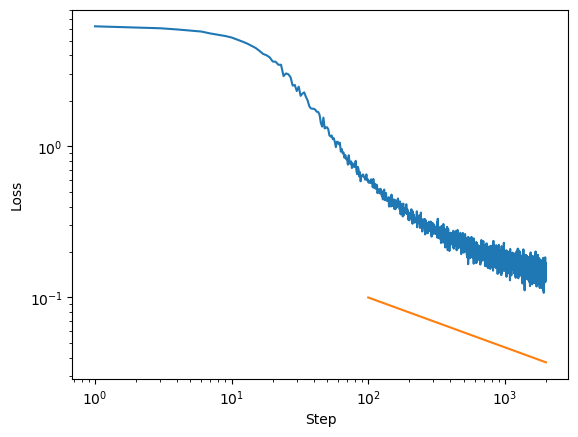

In [49]:
plt.plot(range(1, len(losses) + 1), losses)
plt.plot([100, 2000], [.1, .1/20**0.33])
plt.xlabel('Step')
plt.ylabel('Loss')
plt.xscale('log')
plt.yscale('log')

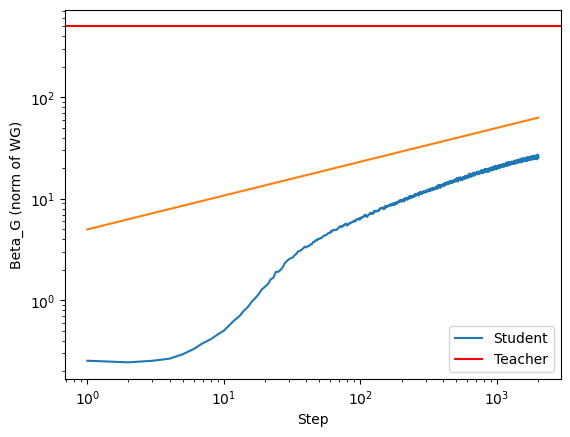

In [50]:
plt.plot(range(1, len(losses) + 1), s_beta_G, label='Student')
plt.axhline(t_cfg.beta_g, label='Teacher', color='red')
plt.plot([1,2000], [5, 5 * 2000 ** (1/3)])
plt.xlabel('Step')
plt.ylabel('Beta_G (norm of WG)')
plt.xscale('log')
plt.yscale('log')
plt.legend()

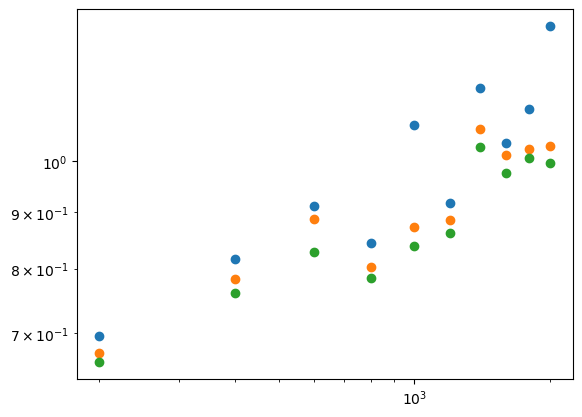

In [51]:
if log_Hessian:
    plt.plot(np.arange(1, num_steps // log_interval + 1) * log_interval, eign_vals.numpy(), 'o')
    plt.xscale('log')
    plt.yscale('log')

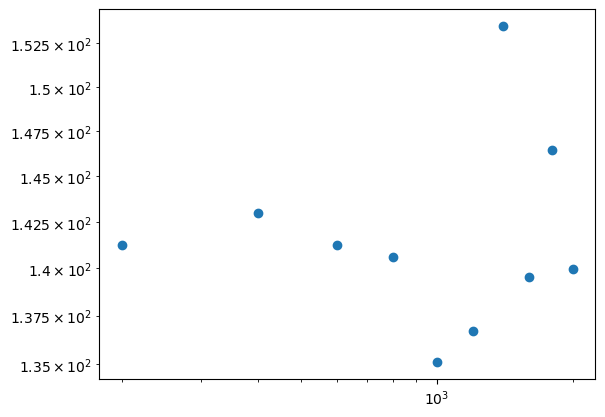

In [52]:
if log_Hessian:
    plt.plot(np.arange(1, num_steps // log_interval + 1) * log_interval, traces.numpy(), 'o')
    plt.xscale('log')
    plt.yscale('log')

Initialization is a good engineering knob for tunning the first training regime.

Hessian trace almost not changing, top eigenvalues are decreasing.
- Hypothesis 1, we need qkv or qk to have increasing Hessian.
- Hypothesis 2, we need no-op to have increasing Hessian, sparse V. [No]
- Hypthesis 3, initialization [No]